# Quantum GNN on QM9: Phases 0–2 (Build, Test, Overfit Check)

This notebook builds the quantum graph neural network and checks that it is correct **before** any real training. It uses the arrays made by `QGNN_01_Subset_GraphDataset.ipynb`.

| Phase | In this notebook |
|---|---|
| 0. Setup | Load `processed/graphs/qm9_gap_subset_qgnn.npz` |
| 1. Build and test | The circuit written twice: a **PennyLane reference** (gate by gate, easy to trust) and a **fast batched simulator in plain PyTorch** (used for training). We check that both give the same numbers and gradients, then run unit tests for permutation invariance, padding and bond sensitivity |
| 2. Overfit check | Train on 100 molecules to confirm that the model can learn at all |

Phase 3 onward (full training, ablations, scaffold split) comes next, using the fast simulator built here.

## The circuit

One qubit per heavy atom (QM9 has at most 9, so 9 qubits). Every molecule runs through the same 9-qubit circuit; unused qubits are padding. Each of the **L layers** does:

```
encode    RY(θ_i) then RZ(φ_i) on atom i's qubit    (θ_i, φ_i) = Linear(23 → 2)(atom features), shared by all atoms
entangle  IsingZZ(w[bond type, l]) on every bonded pair (i, j)     no bond → weight 0 → identity
mix       RX(α_l) then RY(β_l) on every qubit                       trainable, shared by all qubits
```

**Readout:** mean of ⟨Z_i⟩ over the real atoms and mean of ⟨Z_i Z_j⟩ over the bonded pairs → `Linear(2 → 1)` → scaled gap.

The design choices, and why:

- **Weights are shared across atoms and set by bond type, not by position.** This is the same rule a classical GNN follows. All ZZ gates commute, so gate order does not matter, and reordering the atoms gives the same prediction (tested in 4.1).
- **Data re-uploading:** the atom angles are encoded again in every layer. This adds expressive power without adding parameters.
- **The mix layer is required.** ZZ gates are diagonal, so on their own they never change ⟨Z⟩. A rotation that does not commute with Z must come after them for the entanglement to reach the output (demonstrated in 4.4).
- **Mean readout:** the gap is intensive (it does not grow with molecule size).
- **About 75 trainable parameters** at L = 4, against about 156k in the classical GIN.

## 0. Setup

In [1]:
# Run once if packages are missing
# !pip install torch pennylane numpy matplotlib pandas

In [2]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import pennylane as qml

torch.set_default_dtype(torch.float64)   # double precision so the two simulators can be compared to ~1e-12
print("torch", torch.__version__, "| pennylane", qml.__version__)

torch 2.14.1+cu130 | pennylane 0.45.1


In [3]:
DATA      = os.path.join("processed", "graphs", "qm9_gap_subset_qgnn.npz")
META      = os.path.join("processed", "graphs", "qm9_gap_subset_meta.json")
N_QUBITS  = 9          # max heavy atoms in QM9
N_LAYERS  = 4          # default depth
N_BOND_TYPES = 4       # single, double, triple, aromatic (code 0 = no bond)
SEED      = 42
torch.manual_seed(SEED); np.random.seed(SEED)

## 1. Load the quantum-ready arrays

| Array | Shape | Meaning |
|---|---|---|
| `X` | [14000, 9, 23] | atom features, zero rows for padding |
| `bonds` | [14000, 9, 9] | bond code between atoms i and j: 0 none, 1 single, 2 double, 3 triple, 4 aromatic |
| `mask` | [14000, 9] | True for real atoms |
| `y` | [14000] | gap, scaled with the full-train mean and std |
| `random_train`, `scaffold_test`, … | | positions of each split |

In [4]:
q = np.load(DATA)
meta = json.load(open(META))
Y_MEAN, Y_STD = meta["y_mean_eV"], meta["y_std_eV"]

X     = torch.tensor(q["X"], dtype=torch.float64)
BONDS = torch.tensor(q["bonds"].astype(np.int64))
MASK  = torch.tensor(q["mask"])
Y     = torch.tensor(q["y"], dtype=torch.float64)
split = {k: torch.tensor(q[k]) for k in q.files if k.startswith(("random_", "scaffold_"))}

print("X", tuple(X.shape), "| bonds", tuple(BONDS.shape), "| mask", tuple(MASK.shape), "| y", tuple(Y.shape))
print({k: len(v) for k, v in split.items()})
print(f"target scaling: mean {Y_MEAN:.4f} eV, std {Y_STD:.4f} eV")

X (14000, 9, 23) | bonds (14000, 9, 9) | mask (14000, 9) | y (14000,)
{'random_train': 10000, 'random_val': 2000, 'random_test': 2000, 'scaffold_train': 10000, 'scaffold_val': 2000, 'scaffold_test': 2000}
target scaling: mean 6.8583 eV, std 1.2837 eV


## 2. Gates and the fast simulator

A 9-qubit state is a vector of 2⁹ = 512 complex amplitudes. We keep a whole batch of states, shape `[batch, 512]`, and apply gates directly with PyTorch, so autograd gives exact gradients.

- **Qubit order:** qubit 0 is the most significant bit of the basis index, the same convention as PennyLane, so the two simulators can be compared number for number.
- **One-qubit gates:** reshape the state to `[batch, 2^i, 2, 2^(8−i)]` and multiply the middle axis by the 2×2 matrix. Encoding gates differ per molecule and per atom (`[batch, 2, 2]`); mix gates are shared (`[2, 2]`).
- **All ZZ gates at once:** `IsingZZ(w) = exp(−i·w/2·Z⊗Z)` is diagonal. The whole entangling layer is therefore one phase per basis state, `exp(−i/2 · Σ_{i<j} w_ij z_i z_j)`, where z = ±1 is read from the bits of the basis index. This is one matrix product for the whole batch.
- **Measurement:** with probabilities `p = |ψ|²`, ⟨Z_i⟩ = Σ p·z_i and ⟨Z_iZ_j⟩ = Σ p·z_i z_j. These are exact expectation values (no shot noise yet).

In [5]:
def ry(t):
    c, s = torch.cos(t / 2), torch.sin(t / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex128)

def rz(t):
    e = torch.exp(-0.5j * t.to(torch.complex128)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)

def rx(t):
    c, s = torch.cos(t / 2).to(torch.complex128), torch.sin(t / 2).to(torch.complex128)
    return torch.stack([torch.stack([c, -1j * s], -1), torch.stack([-1j * s, c], -1)], -2)

def z_table(n):
    # [2^n, n] matrix of ±1: the Z eigenvalue of each qubit in each basis state (qubit 0 = most significant bit)
    s = torch.arange(2 ** n)
    bits = (s[:, None] >> torch.arange(n - 1, -1, -1)) & 1
    return (1 - 2 * bits).to(torch.float64)

class FastSim:
    # Batched statevector tools for n qubits
    def __init__(self, n):
        self.n = n
        self.Z = z_table(n)                                   # [2^n, n]
        self.iu = torch.triu_indices(n, n, 1)                 # all pairs i < j
        self.ZZ = self.Z[:, self.iu[0]] * self.Z[:, self.iu[1]]   # [2^n, n_pairs]

    def apply_1q(self, psi, U, i):
        B = psi.shape[0]
        p = psi.view(B, 2 ** i, 2, 2 ** (self.n - i - 1))
        if U.dim() == 3:   # a different gate per molecule
            out = torch.einsum("bxy,bayc->baxc", U, p)
        else:              # one shared gate
            out = torch.einsum("xy,bayc->baxc", U, p)
        return out.reshape(B, -1)

sim = FastSim(N_QUBITS)
print("basis states:", sim.Z.shape[0], "| qubit pairs:", sim.iu.shape[1])

basis states: 512 | qubit pairs: 36


## 3. The quantum GNN model

In [6]:
class QGNN(nn.Module):
    def __init__(self, n_layers=N_LAYERS, node_dim=23, n_qubits=N_QUBITS):
        super().__init__()
        self.L, self.n = n_layers, n_qubits
        self.encoder = nn.Linear(node_dim, 2)                                 # atom features -> (theta, phi)
        self.w_zz  = nn.Parameter(0.1 * torch.randn(n_layers, N_BOND_TYPES))  # one ZZ weight per bond type per layer
        self.alpha = nn.Parameter(0.1 * torch.randn(n_layers))                # mix RX angle per layer
        self.beta  = nn.Parameter(0.1 * torch.randn(n_layers))                # mix RY angle per layer
        self.head  = nn.Linear(2, 1)                                          # [mean Z, mean ZZ] -> gap
        self.sim = FastSim(n_qubits)
        self.entangle = True                                                  # switch for the ablation

    def angles(self, x, mask):
        a = self.encoder(x) * mask[..., None]          # padding qubits get angle 0 and stay in |0>
        return a[..., 0], a[..., 1]

    def zz_weights(self, bonds):
        # bond codes [B, n, n] -> ZZ angle for every pair, every layer: [L, B, n_pairs]
        w = torch.cat([torch.zeros(self.L, 1), self.w_zz], 1)   # code 0 (no bond) -> angle 0 -> identity gate
        iu = self.sim.iu
        return w[:, bonds[:, iu[0], iu[1]]] * float(self.entangle)

    def expectations(self, x, bonds, mask):
        B, n, S = x.shape[0], self.n, self.sim
        theta, phi = self.angles(x, mask)
        U_enc = rz(phi) @ ry(theta)                      # RY first, then RZ: [B, n, 2, 2]
        W = self.zz_weights(bonds)
        psi = torch.zeros(B, 2 ** n, dtype=torch.complex128); psi[:, 0] = 1    # |00...0>
        for l in range(self.L):
            for i in range(n):                                                  # encode (re-uploaded each layer)
                psi = S.apply_1q(psi, U_enc[:, i], i)
            psi = psi * torch.exp(-0.5j * (W[l] @ S.ZZ.T))                      # all bond ZZ gates at once
            U_mix = ry(self.beta[l]) @ rx(self.alpha[l])                        # RX first, then RY
            for i in range(n):
                psi = S.apply_1q(psi, U_mix, i)
        p = psi.abs() ** 2
        return p @ S.Z, p @ S.ZZ                         # <Z_i> [B, n], <Z_i Z_j> [B, n_pairs]

    def readout_features(self, x, bonds, mask):
        ez, ezz = self.expectations(x, bonds, mask)
        iu = self.sim.iu
        bonded = (bonds[:, iu[0], iu[1]] > 0).to(ez.dtype)
        m = mask.to(ez.dtype)
        mean_z  = (ez * m).sum(1) / m.sum(1)
        mean_zz = (ezz * bonded).sum(1) / bonded.sum(1).clamp(min=1)
        return torch.stack([mean_z, mean_zz], 1)

    def forward(self, x, bonds, mask):
        return self.head(self.readout_features(x, bonds, mask)).squeeze(1)    # scaled gap

model = QGNN()
n_params = {name: p.numel() for name, p in model.named_parameters()}
print(n_params, "| total:", sum(n_params.values()))

{'w_zz': 16, 'alpha': 4, 'beta': 4, 'encoder.weight': 46, 'encoder.bias': 2, 'head.weight': 2, 'head.bias': 1} | total: 75


## 4. Phase 1: is the circuit correct?

### 4.0 Fast simulator vs PennyLane reference

The PennyLane circuit applies the same gates one by one on `default.qubit`. It takes the angles produced by the **same** model, so any difference comes from the simulation itself. We compare all 9 ⟨Z_i⟩ values and all 36 ⟨Z_iZ_j⟩ values, then the **gradients** of the model output with respect to every parameter.

In [7]:
dev = qml.device("default.qubit", wires=N_QUBITS)
PAIRS = list(zip(sim.iu[0].tolist(), sim.iu[1].tolist()))

@qml.qnode(dev, interface="torch")
def pl_circuit(theta, phi, w_pairs, alpha, beta):
    for l in range(len(alpha)):
        for i in range(N_QUBITS):
            qml.RY(theta[i], wires=i); qml.RZ(phi[i], wires=i)
        for k, (i, j) in enumerate(PAIRS):
            if w_pairs[l, k] != 0:                     # only bonded pairs get a gate
                qml.IsingZZ(w_pairs[l, k], wires=[i, j])
        for i in range(N_QUBITS):
            qml.RX(alpha[l], wires=i); qml.RY(beta[l], wires=i)
    return ([qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
            + [qml.expval(qml.PauliZ(i) @ qml.PauliZ(j)) for (i, j) in PAIRS])

def pl_forward(model, x, bonds, mask):
    # Model prediction for ONE molecule, with the circuit run in PennyLane
    th, ph = model.angles(x[None], mask[None])
    W = model.zz_weights(bonds[None])[:, 0]
    out = torch.stack(pl_circuit(th[0], ph[0], W, model.alpha, model.beta))
    ez, ezz = out[:N_QUBITS], out[N_QUBITS:]
    bonded = (bonds[sim.iu[0], sim.iu[1]] > 0).to(ez.dtype); m = mask.to(ez.dtype)
    feats = torch.stack([(ez * m).sum() / m.sum(), (ezz * bonded).sum() / bonded.sum().clamp(min=1)])
    return model.head(feats).squeeze(), out

print(qml.draw(pl_circuit, max_length=120)(*[t.detach() for t in (
    model.angles(X[:1], MASK[:1])[0][0], model.angles(X[:1], MASK[:1])[1][0],
    model.zz_weights(BONDS[:1])[:1, 0], model.alpha[:1], model.beta[:1])]))

0: ──RY(-0.19)──RZ(-0.13)─╭IsingZZ(0.02)──RX(-0.07)──RY(-0.02)─┤  <Z> ╭<Z@Z> ╭<Z@Z> ╭<Z@Z> ╭<Z@Z> ╭<Z@Z> ╭<Z@Z> ···
1: ──RY(-0.19)──RZ(-0.13)─╰IsingZZ(0.02)──RX(-0.07)──RY(-0.02)─┤  <Z> ╰<Z@Z> │      │      │      │      │      ···
2: ──RY(-0.00)──RZ(-0.00)──RX(-0.07)──────RY(-0.02)────────────┤  <Z>        ╰<Z@Z> │      │      │      │      ···
3: ──RY(-0.00)──RZ(-0.00)──RX(-0.07)──────RY(-0.02)────────────┤  <Z>               ╰<Z@Z> │      │      │      ···
4: ──RY(-0.00)──RZ(-0.00)──RX(-0.07)──────RY(-0.02)────────────┤  <Z>                      ╰<Z@Z> │      │      ···
5: ──RY(-0.00)──RZ(-0.00)──RX(-0.07)──────RY(-0.02)────────────┤  <Z>                             ╰<Z@Z> │      ···
6: ──RY(-0.00)──RZ(-0.00)──RX(-0.07)──────RY(-0.02)────────────┤  <Z>                                    ╰<Z@Z> ···
7: ──RY(-0.00)──RZ(-0.00)──RX(-0.07)──────RY(-0.02)────────────┤  <Z>                                           ···
8: ──RY(-0.00)──RZ(-0.00)──RX(-0.07)──────RY(-0.02)────────────┤  <Z>   

In [8]:
test_ids = [0, 1, 2500, 7000, 13999]          # molecules with different sizes and bond types
rows = []
for i in test_ids:
    # values
    with torch.no_grad():
        ez, ezz = model.expectations(X[i:i+1], BONDS[i:i+1], MASK[i:i+1])
        _, pl_out = pl_forward(model, X[i], BONDS[i], MASK[i])
    val_diff = (pl_out - torch.cat([ez[0], ezz[0]])).abs().max().item()

    # gradients of the prediction w.r.t. all 75 parameters
    model.zero_grad(); model(X[i:i+1], BONDS[i:i+1], MASK[i:i+1]).sum().backward()
    g_fast = torch.cat([p.grad.flatten() for p in model.parameters()])
    model.zero_grad(); pl_forward(model, X[i], BONDS[i], MASK[i])[0].backward()
    g_pl = torch.cat([p.grad.flatten() for p in model.parameters()])
    rows.append({"molecule": i, "atoms": int(MASK[i].sum()), "bonds": int((BONDS[i] > 0).sum() // 2),
                 "max |value diff|": val_diff, "max |grad diff|": (g_fast - g_pl).abs().max().item()})
model.zero_grad()

agree = pd.DataFrame(rows)
display(agree)
assert (agree["max |value diff|"] < 1e-10).all() and (agree["max |grad diff|"] < 1e-10).all()
print("Fast simulator matches PennyLane in values and gradients.")

,molecule,atoms,bonds,max |value diff|,max |grad diff|
0,0,2,1,4.218847e-15,3.552714e-15
1,1,3,2,4.662937e-15,1.021405e-14
2,2500,9,11,2.442491e-15,1.165734e-15
3,7000,9,9,9.992007e-16,3.996803e-15
4,13999,9,12,2.220446e-15,1.720846e-15


Fast simulator matches PennyLane in values and gradients.


### 4.1 Permutation invariance

Relabelling the atoms (shuffling rows of `X`, rows and columns of `bonds`, and the mask) describes the same molecule, so the prediction must not change. We test 20 random relabellings on 50 molecules.

In [9]:
ids = torch.arange(50)
with torch.no_grad():
    base = model(X[ids], BONDS[ids], MASK[ids])
    worst = 0.0
    for _ in range(20):
        perm = torch.randperm(N_QUBITS)
        out = model(X[ids][:, perm], BONDS[ids][:, perm][:, :, perm], MASK[ids][:, perm])
        worst = max(worst, (out - base).abs().max().item())
print(f"max change over 20 relabellings: {worst:.2e}")
assert worst < 1e-10

max change over 20 relabellings: 2.11e-15


### 4.2 Padding has no effect

Two checks:

1. **Garbage in padding:** fill the padded rows of `X` with random numbers. The mask zeroes their angles, so the output must not change.
2. **Fewer qubits:** a molecule with ≤ 8 atoms run on an **8-qubit** circuit must give the same prediction as on the 9-qubit circuit. The extra qubit is unentangled and masked out of the readout, so it cannot affect the result.

In [10]:
ids = torch.where(MASK.sum(1) <= 8)[0][:50]
with torch.no_grad():
    base = model(X[ids], BONDS[ids], MASK[ids])

    X_noisy = X[ids].clone()
    X_noisy[~MASK[ids]] = torch.randn(int((~MASK[ids]).sum()), 23) * 5
    d1 = (model(X_noisy, BONDS[ids], MASK[ids]) - base).abs().max().item()

    m8 = QGNN(n_qubits=8); m8.load_state_dict(model.state_dict())
    d2 = (m8(X[ids, :8], BONDS[ids, :8, :8], MASK[ids, :8]) - base).abs().max().item()

print(f"{len(ids)} molecules with <= 8 atoms")
print(f"garbage in padding rows  -> max change {d1:.2e}")
print(f"8-qubit vs 9-qubit model -> max change {d2:.2e}")
assert d1 < 1e-10 and d2 < 1e-10

50 molecules with <= 8 atoms
garbage in padding rows  -> max change 0.00e+00
8-qubit vs 9-qubit model -> max change 1.44e-15


### 4.3 The circuit does see the bonds

The reverse check: if we delete one bond, or change its type, the prediction must change. Otherwise the graph structure would not be reaching the output.

In [11]:
ids = torch.arange(50)
b_removed, b_changed = BONDS[ids].clone(), BONDS[ids].clone()
for k in range(len(ids)):
    i, j = torch.nonzero(torch.triu(b_removed[k]) > 0)[0]          # first bond of each molecule
    b_removed[k, i, j] = b_removed[k, j, i] = 0
    new = 2 if b_changed[k, i, j] != 2 else 1                      # change its bond type
    b_changed[k, i, j] = b_changed[k, j, i] = new

with torch.no_grad():
    base = model(X[ids], BONDS[ids], MASK[ids])
    d_rm = (model(X[ids], b_removed, MASK[ids]) - base).abs()
    d_ch = (model(X[ids], b_changed, MASK[ids]) - base).abs()
print(f"remove one bond : prediction changed for {(d_rm > 1e-8).sum().item()}/50 molecules, median change {d_rm.median():.2e}")
print(f"change bond type: prediction changed for {(d_ch > 1e-8).sum().item()}/50 molecules, median change {d_ch.median():.2e}")
assert (d_rm > 1e-8).all() and (d_ch > 1e-8).all()

remove one bond : prediction changed for 50/50 molecules, median change 1.28e-02
change bond type: prediction changed for 50/50 molecules, median change 4.79e-03


### 4.4 Why the mix layer is needed

Take a 1-layer circuit and set the mix angles to 0. The ZZ gates are diagonal and commute with the Z measurement, so turning entanglement on or off **must not change ⟨Z_i⟩** at all. With the mix layer active, it does change. This confirms the reasoning behind the design.

In [12]:
m1 = QGNN(n_layers=1)
ids = torch.arange(50)
with torch.no_grad():
    m1.w_zz.fill_(0.8)
    res = {}
    for mix in ["off", "on"]:
        m1.alpha.fill_(0.0 if mix == "off" else 0.7); m1.beta.fill_(0.0 if mix == "off" else 0.4)
        m1.entangle = True;  ez_on, _ = m1.expectations(X[ids], BONDS[ids], MASK[ids])
        m1.entangle = False; ez_off, _ = m1.expectations(X[ids], BONDS[ids], MASK[ids])
        res[mix] = (ez_on - ez_off).abs().max().item()
print(f"mix layer off: entanglement changes <Z_i> by at most {res['off']:.2e}  (no effect, as expected)")
print(f"mix layer on : entanglement changes <Z_i> by up to   {res['on']:.2e}")
assert res["off"] < 1e-10 and res["on"] > 1e-3

mix layer off: entanglement changes <Z_i> by at most 4.44e-16  (no effect, as expected)
mix layer on : entanglement changes <Z_i> by up to   3.38e-01


### 4.5 Speed: fast simulator vs PennyLane

Both use exact statevector simulation. The fast version processes a whole batch at once and skips PennyLane's per-gate overhead.

In [13]:
B = 128
xb, bb, mb, yb = X[:B], BONDS[:B], MASK[:B], Y[:B]
t0 = time.perf_counter()
for _ in range(5):
    model.zero_grad(); ((model(xb, bb, mb) - yb) ** 2).mean().backward()
fast_ms = (time.perf_counter() - t0) / 5 / B * 1000

t0 = time.perf_counter()
for i in range(8):
    model.zero_grad(); pl_forward(model, X[i], BONDS[i], MASK[i])[0].backward()
pl_ms = (time.perf_counter() - t0) / 8 * 1000
model.zero_grad()

print(f"fast simulator: {fast_ms:.2f} ms per molecule (forward + backward, batch {B})")
print(f"PennyLane     : {pl_ms:.1f} ms per molecule (forward + backward)")
print(f"speed-up ≈ {pl_ms / fast_ms:.0f}x")
print(f"one epoch over 10,000 training molecules ≈ {10_000 * fast_ms / 1000:.0f} s (fast) vs "
      f"{10_000 * pl_ms / 1000 / 60:.0f} min (PennyLane)")

fast simulator: 0.88 ms per molecule (forward + backward, batch 128)
PennyLane     : 77.2 ms per molecule (forward + backward)
speed-up ≈ 88x
one epoch over 10,000 training molecules ≈ 9 s (fast) vs 13 min (PennyLane)


## 5. Phase 2: overfit check

Before training on 10,000 molecules, we train on just **100** and check that the training error falls well below a trivial baseline, which always predicts the mean gap. With only ~75 parameters the model is not expected to memorise 100 molecules exactly. The questions are whether learning happens and whether deeper circuits fit better. We try L = 2, 4 and 6 layers, using full-batch Adam with lr 0.05 for 600 steps.

This is a training-set check only; it says nothing yet about generalisation.

Mean-predictor baseline MAE on these 100 molecules: 1.161 eV


,layers,parameters,start MAE (eV),best MAE (eV),final MAE (eV),time (s)
0,2,63,1.682,0.282,0.282,15.970
1,4,75,1.087,0.236,0.246,33.833
2,6,87,1.088,0.250,0.295,47.936


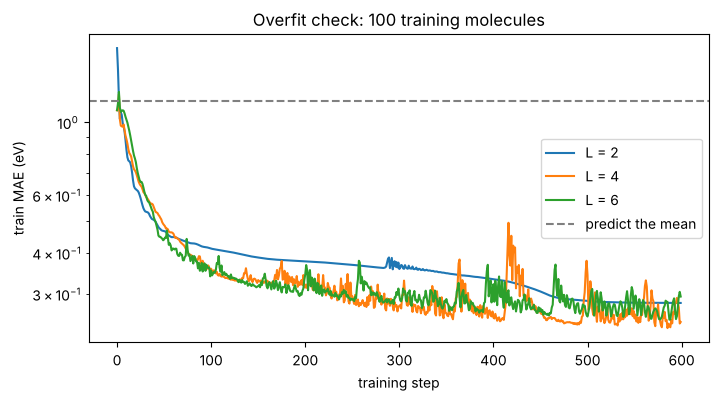

In [14]:
sel = split["random_train"][:100]
xs, bs, ms, ys = X[sel], BONDS[sel], MASK[sel], Y[sel]
baseline_mae = (ys - ys.mean()).abs().mean().item() * Y_STD

curves, summary = {}, []
for L in [2, 4, 6]:
    torch.manual_seed(SEED)
    m = QGNN(n_layers=L)
    opt = torch.optim.Adam(m.parameters(), lr=0.05)
    hist = []
    t0 = time.perf_counter()
    for step in range(600):
        opt.zero_grad()
        pred = m(xs, bs, ms)
        loss = ((pred - ys) ** 2).mean()
        loss.backward(); opt.step()
        hist.append((pred.detach() - ys).abs().mean().item() * Y_STD)
    curves[L] = hist
    summary.append({"layers": L, "parameters": sum(p.numel() for p in m.parameters()),
                    "start MAE (eV)": hist[0], "best MAE (eV)": min(hist), "final MAE (eV)": hist[-1],
                    "time (s)": time.perf_counter() - t0})

summary = pd.DataFrame(summary)
print(f"Mean-predictor baseline MAE on these 100 molecules: {baseline_mae:.3f} eV")
display(summary.round(3))

plt.figure(figsize=(8, 4))
for L, h in curves.items():
    plt.plot(h, label=f"L = {L}")
plt.axhline(baseline_mae, color="grey", ls="--", label="predict the mean")
plt.yscale("log"); plt.xlabel("training step"); plt.ylabel("train MAE (eV)")
plt.title("Overfit check: 100 training molecules"); plt.legend(); plt.show()

assert (summary["final MAE (eV)"] < 0.5 * baseline_mae).all(), "model is not learning"

## 6. Summary of Phases 0–2

- **Correctness:** the fast PyTorch simulator matches the PennyLane gate-by-gate circuit to about 1e-15, in both values and gradients.
- **Symmetry:** predictions do not change when atoms are relabelled, when garbage is put in padding rows, or when a ≤ 8-atom molecule runs on 8 instead of 9 qubits.
- **Graph sensitivity:** removing a bond or changing its type changes the prediction, and the mix layer is confirmed to be needed for entanglement to reach the output.
- **Speed:** the fast simulator is much faster than PennyLane (section 4.5), so full 10k-molecule epochs are practical.
- **Learning:** on 100 molecules every depth brings the training MAE from about 1.1 eV (the mean-predictor baseline) down to roughly 0.25–0.30 eV, about 4× lower. With ~75 parameters it does not memorise the set, which is expected. Extra depth did **not** automatically fit better at this budget (L = 4 ended lowest), so depth will be chosen on validation data in Phase 3.
- **Training is noisy at lr 0.05** (spikes in the curve). Phase 3 should use a lower learning rate or a scheduler, plus mini-batches.

**Next (Phase 3):** train on the 10k random split with early stopping on validation MAE, and sweep L = 1–4 and 1 vs 2 angles per qubit. Then run the ablations: no entanglement, bond-type-blind ZZ, the plain 8-PCA-angle circuit, and a classical model with ~75 parameters.